# LusoEnergia — Partes I e II
**Janela do grupo:** 2008-05-01 a 2009-11-01 (seed 107335), gerada por `preparar_dataset.py` a partir do ficheiro original.


## Parte I — Fundação

In [103]:
import sys
sys.path.insert(0, "../src")          # funcoes partilhadas vivem em src/utils.py

import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from src.utils import (
    carregar_dados, validar_dados, DICIONARIO_DADOS,        # 1.1
    reindexar_minuto, tabela_lacunas, missing_por_dia,      # 1.2 (grelha e lacunas)
    tratar_missing, dias_validos,                           # 1.2 (tratamento)
)

pd.set_option("display.width", 120)

### 1.1 Carregamento e tipagem

**Tipos escolhidos (escala de Stevens).** Todas as variáveis são medidas físicas com zero absoluto, logo **escala de razão**. Ficam em `float64` porque precisam de representar `NaN` (um `int64` não o permite) e a memória (~44 MB) não justifica `float32`. As submedições estão em **Wh por minuto**, não em kW.

In [104]:
pd.DataFrame(DICIONARIO_DADOS).T[["dtype", "unidade", "escala", "nota"]]

,dtype,unidade,escala,nota
Global_active_power,float64,kW,razao,Potencia ativa media do minuto. Nao pode ser n...
Global_reactive_power,float64,kVAr,razao,Potencia reativa media do minuto. Nao pode ser...
Voltage,float64,V,razao,Tensao media. Rede de ~240 V: valores muito fo...
Global_intensity,float64,A,razao,Intensidade de corrente media do minuto.
Sub_metering_1,float64,Wh,razao,"Cozinha (forno, micro-ondas, ...). ATENCAO: Wh..."
Sub_metering_2,float64,Wh,razao,"Lavandaria (maquina de lavar, secador, frigori..."
Sub_metering_3,float64,Wh,razao,Aquecedor de agua e ar condicionado.


In [105]:
df = carregar_dados()
print(f"{len(df):,} linhas | {df.index.min()} -> {df.index.max()}")
df.head()

790,560 linhas | 2008-05-01 00:00:00 -> 2009-10-31 23:59:00


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2008-05-01 00:00:00,0.324,0.084,241.38,1.4,0.0,0.0,0.0
2008-05-01 00:01:00,0.324,0.082,241.16,1.4,0.0,0.0,1.0
2008-05-01 00:02:00,0.324,0.082,241.28,1.4,0.0,0.0,1.0
2008-05-01 00:03:00,0.324,0.084,241.40,1.4,0.0,0.0,0.0
2008-05-01 00:04:00,0.322,0.084,241.21,1.4,0.0,0.0,1.0


In [106]:
df.dtypes

Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object

### 1.2 Auditoria de qualidade

- Janela: 2008-05-01 a 2009-10-31 (790 560 minutos). Faltam **4 407 minutos (0,56 %)**, **os mesmos nas 7 variáveis** (todas falham em simultâneo).
- Há **26 lacunas**: 19 curtas (≤ 5 min, 30 min no total), 5 médias (6–70 min) e 2 longas (> 3 h): **55 h (13–15 jun 2009)** e **15 h (13 ago 2009)**. Estas duas somam 4 196 dos 4 407 minutos em falta (95 %).
- Por período: o missing mensal é ≈ 0 % em quase todos os meses; concentra-se em **jun/2009 (7,65 %)** e **ago/2009 (2,00 %)**. Os restantes meses ficam abaixo de 0,2 %.
- Dias praticamente sem leituras: **13/06/2009 (98 %)** e **14/06/2009 (100 %)**; também 15/06/2009 (32 %) e 13/08/2009 (62 %). Ver `missing.png` (função `plot_missing`).

In [107]:
def resumo_missing(df):
    """Missing por variavel (contagem e %)."""
    n = df.isna().sum()
    return pd.DataFrame({"n_missing": n, "pct": (100 * n / len(df)).round(3)})


def missing_por_periodo(df, freq="MS"):
    """Missing (%) por variavel e por periodo (mes por defeito)."""
    d = reindexar_minuto(df)
    return (100 * d.isna().groupby(pd.Grouper(freq=freq)).mean()).round(2)


def classificar_lacunas(t, curta_max_min=5, media_max_min=180):
    """Classifica cada lacuna: curta (<=5 min), media (6-180 min) ou longa (>180 min)."""
    t = t.copy()
    t["tipo"] = np.select(
        [t["minutos"] <= curta_max_min, t["minutos"] <= media_max_min],
        ["curta", "media"], default="longa")
    return t

In [108]:
resumo_missing(df)

,n_missing,pct
Global_active_power,4407,0.557
Global_reactive_power,4407,0.557
Voltage,4407,0.557
Global_intensity,4407,0.557
Sub_metering_1,4407,0.557
Sub_metering_2,4407,0.557
Sub_metering_3,4407,0.557


In [109]:
mensal = missing_por_periodo(df)
mensal["Global_active_power"].round(2).to_frame("% em falta").T

datetime,2008-05-01,2008-06-01,2008-07-01,2008-08-01,2008-09-01,2008-10-01,2008-11-01,2008-12-01,2009-01-01,2009-02-01,2009-03-01,2009-04-01,2009-05-01,2009-06-01,2009-07-01,2009-08-01,2009-09-01,2009-10-01
% em falta,0.0,0.0,0.0,0.0,0.0,0.1,0.02,0.16,0.0,0.16,0.0,0.0,0.01,7.65,0.01,2.0,0.01,0.0


In [110]:
lacunas = classificar_lacunas(tabela_lacunas(df))
display(lacunas.groupby("tipo")["minutos"].agg(n_lacunas="count", minutos_total="sum", maximo="max"))
lacunas[lacunas["tipo"] != "curta"]

,n_lacunas,minutos_total,maximo
tipo,,,
curta,19,30,4
longa,2,4196,3305
media,5,181,70


,inicio,fim,minutos,duracao_horas,tipo
5,2008-10-25 10:28:00,2008-10-25 11:10:00,43,0.72,media
6,2008-11-10 17:43:00,2008-11-10 17:48:00,6,0.10,media
9,2008-12-10 10:48:00,2008-12-10 11:57:00,70,1.17,media
12,2009-02-01 16:29:00,2009-02-01 17:06:00,38,0.63,media
14,2009-02-17 10:06:00,2009-02-17 10:29:00,24,0.40,media
20,2009-06-13 00:30:00,2009-06-15 07:34:00,3305,55.08,longa
22,2009-08-13 05:00:00,2009-08-13 19:50:00,891,14.85,longa


Figura: missing por mês (cima) e calendário dia a dia (baixo).

In [111]:
def plot_missing(df, caminho_png=None, coluna="Global_active_power"):
    """Figura de relatorio sobre dados em falta (2 paineis, mesma escala temporal):
    (cima) % de minutos em falta por mes; (baixo) calendario mes x dia do mes com a
    fracao de cada dia em falta. Escala sequencial de um so tom (azul)."""
    import calendar

    import matplotlib.pyplot as plt
    from matplotlib.colors import LinearSegmentedColormap

    TINTA, TINTA_2, GRELHA = "#2b2b28", "#6b6a64", "#e4e3de"
    AZUL = "#2a78d6"
    cmap = LinearSegmentedColormap.from_list("azul", ["#e9f1fc", "#9ec5f4", "#3987e5", "#184f95", "#0d366b"])

    f = missing_por_dia(df, coluna)                      # fracao por dia
    mensal = missing_por_periodo(df)[coluna]             # % por mes
    meses = mensal.index
    MESES_PT = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
    rotulos = [f"{MESES_PT[m.month - 1]}/{m:%y}" for m in meses]

    # matriz mes x dia-do-mes (NaN onde o dia nao existe)
    mat = np.full((len(meses), 31), np.nan)
    for i, m in enumerate(meses):
        for d in range(1, calendar.monthrange(m.year, m.month)[1] + 1):
            mat[i, d - 1] = f.get(pd.Timestamp(m.year, m.month, d), np.nan)

    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(11, 8.2), gridspec_kw={"height_ratios": [1, 1.9], "hspace": 0.38})
    fig.patch.set_facecolor("white")

    # --- painel 1: % em falta por mes ------------------------------------
    x = np.arange(len(meses))
    ax1.bar(x, mensal.values, width=0.55, color=AZUL)
    ax1.set_xticks(x, rotulos, rotation=45, ha="right", fontsize=9, color=TINTA_2)
    ax1.set_ylabel("Minutos em falta (% do mes)", fontsize=9, color=TINTA_2)
    ax1.grid(axis="y", color=GRELHA, lw=0.8)
    ax1.set_axisbelow(True)
    for sp in ("top", "right", "left"):
        ax1.spines[sp].set_visible(False)
    ax1.spines["bottom"].set_color(GRELHA)
    ax1.tick_params(axis="y", labelsize=9, colors=TINTA_2, length=0)
    ax1.tick_params(axis="x", length=0)
    for i in np.argsort(mensal.values)[-2:]:
        ax1.annotate(f"{mensal.values[i]:.2f}%", (x[i], mensal.values[i]), xytext=(0, 4),
                     textcoords="offset points", ha="center", fontsize=9, color=TINTA)
    ax1.set_title("Concentracao de dados em falta por mês",
                  loc="left", fontsize=12, color=TINTA, fontweight="bold")

    # --- painel 2: calendario mes x dia ----------------------------------
    im = ax2.imshow(np.ma.masked_invalid(mat), cmap=cmap, vmin=0, vmax=1, aspect="auto",
                    interpolation="nearest")
    ax2.set_xticks(range(0, 31, 2), [str(d) for d in range(1, 32, 2)], fontsize=8.5, color=TINTA_2)
    ax2.set_yticks(range(len(meses)), rotulos, fontsize=9, color=TINTA_2)
    ax2.set_xlabel("Dia do mês", fontsize=9, color=TINTA_2)
    ax2.set_xticks(np.arange(-0.5, 31, 1), minor=True)
    ax2.set_yticks(np.arange(-0.5, len(meses), 1), minor=True)
    ax2.grid(which="minor", color="white", lw=2)           # 2px de folga entre celulas
    ax2.tick_params(which="both", length=0)
    for sp in ax2.spines.values():
        sp.set_visible(False)
    for i in range(len(meses)):
        for j in range(31):
            v = mat[i, j]
            if v > 0.3:
                ax2.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=6.5,
                         color="white" if v > 0.5 else TINTA)
    ax2.set_title("Percentagem de dias em falta",
                  loc="left", fontsize=12, color=TINTA, fontweight="bold")
    cb = fig.colorbar(im, ax=ax2, fraction=0.025, pad=0.02)
    cb.set_label("Fracao do dia em falta", fontsize=9, color=TINTA_2)
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=8.5, colors=TINTA_2, length=0)

    fig.text(0.01, 0.005, f"Variavel: {coluna} (as 7 variaveis falham em simultaneo). "
             f"Janela: {df.index.min():%d/%m/%Y} a {df.index.max():%d/%m/%Y}.",
             fontsize=8, color=TINTA_2)
    if caminho_png:
        fig.savefig(caminho_png, dpi=160, bbox_inches="tight", facecolor="white")
    return fig

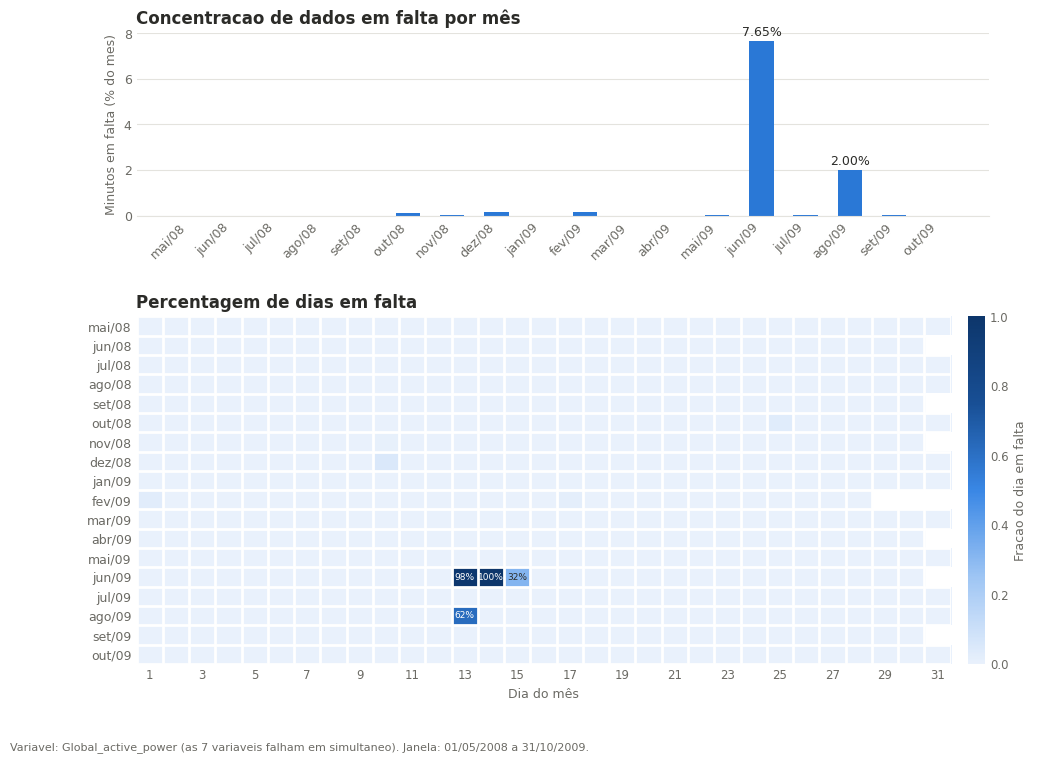

In [112]:
fig = plot_missing(df, "figures/missing.png")
plt.show()

#### Mecanismo provável

**Conclusão: não é MCAR; o mais plausível é MAR para as lacunas curtas e MNAR (não excluível) para as longas.**

Evidência:

1. **Falha simultânea das 7 variáveis**: aponta para falha do sistema de registo/comunicação (ou corte de energia) e não para avaria de um sensor individual.
2. **Teste de permutação**: o consumo médio nos 30 min *anteriores* às lacunas é **1,56 kW**, contra **1,01 kW** em instantes aleatórios (p ≈ 0,003). O aparecimento de lacunas depende do consumo observado, o que **rejeita MCAR**.
3. **Padrões temporais**: 6 das 26 lacunas começam no **dia 13 do mês** e 8 num **domingo** (esperado ≈ 3,7 por dia da semana). Sugere uma causa parcialmente sistemática (p. ex. rotina de manutenção/recolha de dados) — hipótese a confirmar, a amostra é pequena (26).
4. **O que não se consegue testar**: se as lacunas longas ocorreram *porque* o consumo era anómalo durante a falha (p. ex. sobrecarga que desligou o contador, ou corte de eletricidade), isso é MNAR e, por definição, não é verificável com os dados observados.

Nota de cautela: o p-valor mostra associação, não causa; com 26 lacunas, o teste tem pouco poder para padrões mais finos.

In [113]:
def teste_mecanismo(df, n_perm=2000, seed=42, coluna="Global_active_power"):
    """Testa se o missing depende do consumo observado (contra MCAR).

    Teste de permutacao: o consumo medio nos 30 min ANTES de cada lacuna e
    comparado com o de instantes aleatorios (sem missing). Se o p-valor for
    pequeno, o aparecimento de lacunas esta associado a valores observados
    -> nao e MCAR (e pelo menos MAR).
    """
    rng = np.random.default_rng(seed)
    s = reindexar_minuto(df)[coluna]
    t = tabela_lacunas(df, coluna)
    antes = np.array([s.loc[: r.inicio - pd.Timedelta("1min")].dropna().tail(30).mean() for r in t.itertuples()])
    pos = np.flatnonzero(~s.isna().values)
    pos = pos[pos > 60]
    perm = np.array([np.mean([s.iloc[j - 30:j].mean() for j in rng.choice(pos, len(t))]) for _ in range(n_perm)])
    return {
        "consumo medio antes das lacunas (kW)": round(float(antes.mean()), 3),
        "consumo medio em instantes aleatorios (kW)": round(float(perm.mean()), 3),
        "p-valor (unilateral)": round(float(np.mean(perm >= antes.mean())), 4),
        "lacunas a dia 13 do mes": int((t["inicio"].dt.day == 13).sum()),
        "lacunas ao domingo": int((t["inicio"].dt.dayofweek == 6).sum()),
        "n lacunas": len(t),
    }

In [114]:
pd.Series(teste_mecanismo(df), name="valor").to_frame()

,valor
consumo medio antes das lacunas (kW),1.555
consumo medio em instantes aleatorios (kW),1.006
p-valor (unilateral),0.003
lacunas a dia 13 do mes,6.000
lacunas ao domingo,8.000
n lacunas,26.000


#### Estratégia de tratamento

Para escolher o limiar, simularam-se lacunas de 1 min a 2 dias em zonas sem missing e mediu-se o erro absoluto médio (kW) de quatro métodos (`avaliar_imputacao`):

| Lacuna (min) | Interp. linear | Último valor | Perfil hora×dia sem. | Média global |
|---:|---:|---:|---:|---:|
| 1 | **0,06** | 0,06 | 0,58 | 0,75 |
| 5 | **0,13** | 0,19 | 0,53 | 0,70 |
| 60 | **0,31** | 0,43 | 0,56 | 0,75 |
| 180 | **0,47** | 0,63 | 0,57 | 0,74 |
| 720 (12 h) | 0,77 | 0,89 | **0,59** | 0,75 |
| 2 880 (2 dias) | 0,83 | 0,87 | **0,60** | 0,77 |

Decisão:

- **Lacunas de 1 min (e até 3 h): interpolação linear no tempo.** Para 1 min o erro (≈ 0,06 kW) é mínimo e muito inferior à média global (0,75 kW); o consumo muda pouco de um minuto para o seguinte. Até 3 h continua a bater os alternativos, mas o erro cresce, por isso as linhas imputadas ficam **marcadas** (`imputado`) para fazer análises de sensibilidade.
- **Lacunas de 2 dias (e > 3 h): não imputar; manter NaN e excluir os dias afetados** das agregações diárias (`dias_validos`: 13, 14, 15 jun e 13 ago de 2009). Para lacunas desta dimensão nenhum método melhora o erro «de ignorância» (~0,6 kW, o desvio típico do consumo), e a interpolação linear entre dois pontos separados por dois dias desenha uma reta sem relação com o consumo real. Imputar criaria dados que não foram observados e enviesaria a sazonalidade e as previsões da Parte III.
- **Alternativa rejeitada**: preencher as lacunas longas com o perfil médio hora × dia da semana. Tem erro estável (~0,6 kW), mas suaviza os picos e enviesa variância/autocorrelação, o que é precisamente o que a Parte III e o monitor de anomalias da Parte IV exploram; além disso, se as lacunas forem MNAR, o perfil médio não reflete o que se passou.
- **Alternativa rejeitada**: remover linhas com NaN sem reindexar. Escondia as lacunas e deixava a série irregular, o que quebra lags, médias móveis e replay do fluxo.

In [115]:
def avaliar_imputacao(df, comprimentos=(1, 2, 5, 10, 30, 60, 180, 720, 2880),
                      n_sim=200, seed=42, coluna="Global_active_power"):
    """Simula lacunas de varios comprimentos em zonas SEM missing e mede o erro
    absoluto medio (kW) de 4 metodos: interpolacao linear, ultimo valor (ffill),
    perfil medio hora x dia da semana e media global. Justifica o limiar de tratamento."""
    rng = np.random.default_rng(seed)
    s = reindexar_minuto(df)[coluna]
    perfil = s.groupby([s.index.dayofweek, s.index.hour]).mean()
    media = s.mean()
    linhas = []
    for L in comprimentos:
        erros = {"linear": [], "ffill": [], "perfil_sazonal": [], "media_global": []}
        n = 0
        while n < n_sim:
            i = int(rng.integers(200, len(s) - L - 200))
            w = s.iloc[i - 120:i + L + 120]
            if w.isna().any():
                continue
            n += 1
            m = w.copy()
            m.iloc[120:120 + L] = np.nan
            real = w.iloc[120:120 + L]
            sazonal = pd.Series(perfil.reindex(list(zip(real.index.dayofweek, real.index.hour))).values, index=real.index)
            erros["linear"].append((m.interpolate("time").iloc[120:120 + L] - real).abs().mean())
            erros["ffill"].append((m.ffill().iloc[120:120 + L] - real).abs().mean())
            erros["perfil_sazonal"].append((sazonal - real).abs().mean())
            erros["media_global"].append((media - real).abs().mean())
        linhas.append({"comprimento_min": L, **{k: round(float(np.mean(v)), 3) for k, v in erros.items()}})
    return pd.DataFrame(linhas).set_index("comprimento_min")

In [116]:
# Simulação: erro absoluto médio (kW) de cada método por comprimento da lacuna
avaliar_imputacao(df)

,linear,ffill,perfil_sazonal,media_global
comprimento_min,,,,
1,0.062,0.060,0.583,0.747
2,0.073,0.097,0.620,0.760
5,0.129,0.186,0.526,0.696
10,0.171,0.212,0.591,0.748
30,0.293,0.421,0.598,0.758
60,0.313,0.427,0.560,0.747
180,0.469,0.632,0.569,0.743
720,0.771,0.886,0.590,0.749
2880,0.830,0.874,0.603,0.766


In [117]:
tratado, imputado = tratar_missing(df)      # <= 3 h: interpolação linear; > 3 h: NaN
print(f"Minutos imputados: {imputado.sum()} | NaN que ficam: {tratado['Global_active_power'].isna().sum()}")

validos = dias_validos(tratado)
todos = missing_por_dia(tratado).index
print("Dias excluídos das agregações diárias:", list(todos.difference(validos).date))

Minutos imputados: 211 | NaN que ficam: 4196
Dias excluídos das agregações diárias: [datetime.date(2009, 6, 13), datetime.date(2009, 6, 14), datetime.date(2009, 6, 15), datetime.date(2009, 8, 13)]


### 1.3 Sumário estatístico com juízo

Usam-se apenas os minutos **observados** (os 4 407 minutos em falta são ignorados nas estatísticas; os imputados na 1.2 não entram aqui, para não contaminar medidas de forma e de outliers).

In [118]:
# Configuração da secção 1.3
VARS = list(DICIONARIO_DADOS)                       # as 7 variáveis
VARS_OUT = ["Global_active_power", "Global_reactive_power", "Voltage", "Global_intensity"]
SUBS = ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
VAR_ESTRAT = "Global_active_power"                  # variável do pivot hora x dia da semana
MIN_EPISODIO = 5                                    # minutos consecutivos para um extremo ser "evento"
DIAS = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
MESES_PT = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
AZUL, LARANJA, TINTA, TINTA_2, GRELHA = "#2a78d6", "#e07b24", "#2b2b28", "#6b6a64", "#e4e3de"
CMAP = LinearSegmentedColormap.from_list("azul", ["#e9f1fc", "#9ec5f4", "#3987e5", "#184f95", "#0d366b"])

def estilo(ax):
    """Eixos discretos: sem moldura, grelha leve."""
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    for sp in ("left", "bottom"):
        ax.spines[sp].set_color(GRELHA)
    ax.tick_params(colors=TINTA_2, labelsize=9, length=0)
    ax.grid(axis="y", color=GRELHA, lw=0.8)
    ax.set_axisbelow(True)

#### Localização e dispersão adequadas à forma

In [119]:
def mad(s):
    """MAD escalado (x1.4826): comparável ao desvio-padrão se a distribuição for normal."""
    s = pd.Series(s).dropna()
    return 1.4826 * np.median(np.abs(s - np.median(s)))


def sumario(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    skew = s.skew()
    return {
        "n": len(s), "média": s.mean(), "mediana": s.median(), "desvio-padrão": s.std(),
        "IQR": q3 - q1, "MAD (escalado)": mad(s), "min": s.min(), "max": s.max(),
        "skewness": skew, "curtose (excesso)": s.kurt(), "média − mediana": s.mean() - s.median(),
        "medida a usar": "média ± dp" if abs(skew) < 0.5 else "mediana + IQR",
    }


resumo = pd.DataFrame({v: sumario(df[v]) for v in VARS})
resumo.T.round(3)

,n,média,mediana,desvio-padrão,IQR,MAD (escalado),min,max,skewness,curtose (excesso),média − mediana,medida a usar
Global_active_power,786153,1.008626,0.518,0.992359,1.164,0.483328,0.076,11.122,1.891371,4.874668,0.490626,mediana + IQR
Global_reactive_power,786153,0.129115,0.104,0.114135,0.15,0.124538,0.0,1.24,1.183603,2.230965,0.025115,mediana + IQR
Voltage,786153,241.126183,241.15,2.811985,3.38,2.505594,223.2,253.94,-0.217779,1.373373,-0.023817,média ± dp
Global_intensity,786153,4.286298,2.4,4.155332,4.6,2.37216,0.2,48.4,1.949162,5.267556,1.886298,mediana + IQR
Sub_metering_1,786153,1.077465,0.0,6.062161,0.0,0.0,0.0,82.0,6.064013,36.833896,1.077465,mediana + IQR
Sub_metering_2,786153,1.116045,0.0,5.245064,1.0,0.0,0.0,77.0,7.949404,73.632673,1.116045,mediana + IQR
Sub_metering_3,786153,6.198697,1.0,8.303254,18.0,1.4826,0.0,31.0,0.853549,-1.010346,5.198697,mediana + IQR


**Leitura.** O skewness é > 0,5 em 6 das 7 variáveis; só a **tensão** é aproximadamente simétrica (skew −0,22, média ≈ mediana), e é a única onde faz sentido reportar média ± desvio-padrão.

- **Potência ativa:** mediana 0,52 kW contra média 1,01 kW (a média é quase o dobro). A distribuição é **bimodal** (um modo de repouso perto de 0,3 kW e outro de utilização ativa perto de 1,5 kW), por isso nenhuma medida de localização descreve bem «o consumo típico»: descrevemos com mediana + IQR e mostramos a forma completa. **Exceção:** para planear compras de energia o que interessa é o consumo total, e esse é dado pela média (a soma é média × n).
- **Potência reativa e intensidade:** mesma forma assimétrica (skew 1,2 e 1,9). A intensidade segue a potência ativa (I ≈ P / V, com V ≈ 241 V: 0,52 kW ↔ ~2,2 A, perto da mediana de 2,4 A), logo é em boa parte informação redundante.
- **Submedições:** a mediana e o IQR são 0 (Sub 1 e 2) porque na maior parte dos minutos não há consumo; a média e o desvio-padrão descrevem mal. Reportam-se, em alternativa, a % de minutos com consumo e a média quando há consumo.

In [120]:
# Submedições: a mediana e o IQR são 0 porque, na maioria dos minutos, não há consumo
pd.DataFrame({
    "% minutos com consumo > 0": (100 * (df[SUBS] > 0).mean()).round(1),
    "média quando > 0 (Wh)": df[SUBS].where(df[SUBS] > 0).mean().round(2),
    "máximo (Wh)": df[SUBS].max(),
})

,% minutos com consumo > 0,média quando > 0 (Wh),máximo (Wh)
Sub_metering_1,8.1,13.17,82.0
Sub_metering_2,28.6,3.87,77.0
Sub_metering_3,64.9,9.49,31.0


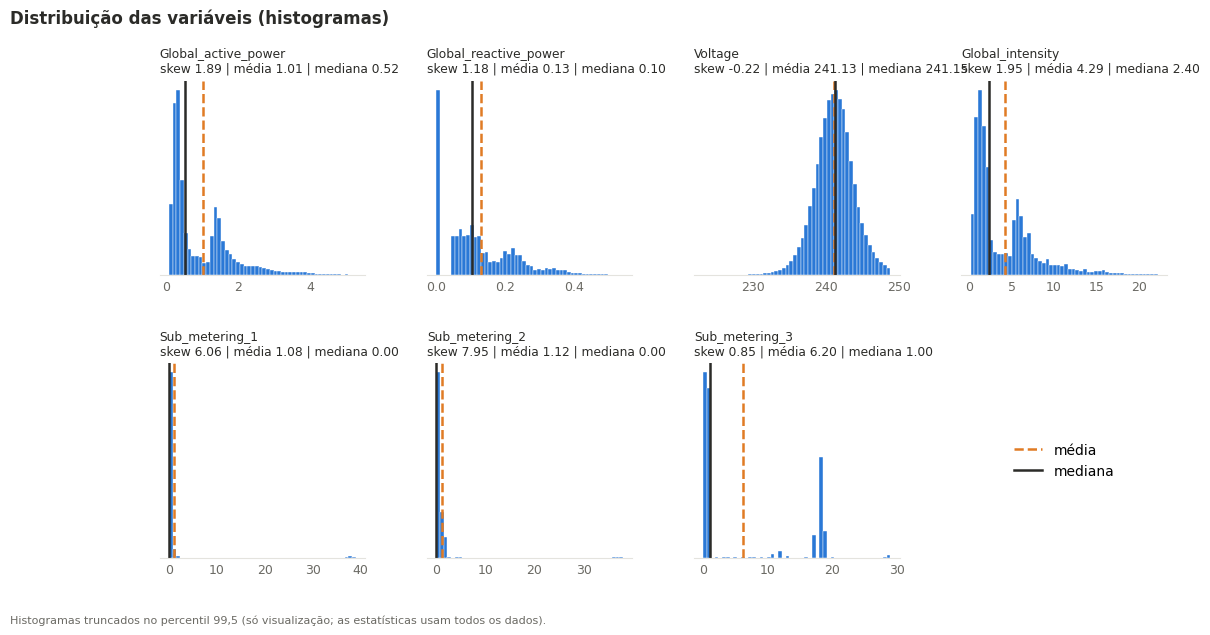

In [121]:
def plot_distribuicoes(df, variaveis, caminho_png=None):
    """Histograma de cada variável com média (tracejada) e mediana (cheia)."""
    fig, axes = plt.subplots(2, 4, figsize=(13, 6.2), gridspec_kw={"hspace": 0.45, "wspace": 0.3})
    for ax, v in zip(axes.flat, variaveis):
        s = df[v].dropna()
        corte = s.quantile(0.995)                       # só para a visualização (cauda longa)
        ax.hist(s[s <= corte], bins=50, color=AZUL, edgecolor="white", lw=0.3)
        ax.axvline(s.mean(), color=LARANJA, ls="--", lw=1.8)
        ax.axvline(s.median(), color=TINTA, lw=1.8)
        ax.set_title(f"{v}\nskew {s.skew():.2f} | média {s.mean():.2f} | mediana {s.median():.2f}",
                     fontsize=8.8, color=TINTA, loc="left")
        ax.set_yticks([])
        estilo(ax); ax.grid(False)
        ax.spines["left"].set_visible(False)
    for ax in axes.flat[len(variaveis):]:
        ax.axis("off")
    from matplotlib.lines import Line2D
    axes.flat[-1].legend(handles=[Line2D([0], [0], color=LARANJA, ls="--", lw=1.8, label="média"),
                                  Line2D([0], [0], color=TINTA, lw=1.8, label="mediana")],
                         frameon=False, fontsize=10, loc="center")
    fig.suptitle("Distribuição das variáveis (histogramas)",
                 x=0.01, ha="left", fontsize=12, fontweight="bold", color=TINTA, y=0.995)
    fig.text(0.01, 0.005, "Histogramas truncados no percentil 99,5 (só visualização; as estatísticas usam todos os dados).",
             fontsize=8, color=TINTA_2)
    if caminho_png:
        fig.savefig(caminho_png, dpi=150, bbox_inches="tight", facecolor="white")
    return fig


fig = plot_distribuicoes(df, VARS, "figures/distribuicoes.png")
plt.show()

#### Outliers: regra 1.5×IQR e z-score robusto

Compara-se com a regra 1.5×IQR, com o z-score robusto (mediana/MAD, limiar 3,5), com o mesmo z robusto na escala logarítmica e com o z-score clássico (média/desvio, limiar 3), só para mostrar o *masking*. As submedições ficam de fora: com MAD = 0 e IQR = 0 qualquer valor > 0 seria «outlier», e são analisadas à parte. Um **extremo** é um minuto marcado pelo IQR **e** pelo z robusto (critério conservador).

In [122]:
def outliers_iqr(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    i = q3 - q1
    return (s < q1 - k * i) | (s > q3 + k * i)


def z_robusto(s):
    """(x - mediana) / MAD escalado. Devolve NaN se MAD = 0 (z não aplicável)."""
    m = mad(s)
    return (s - s.median()) / m if m > 0 else pd.Series(np.nan, index=s.index)


flags, linhas = {}, []
for v in VARS_OUT:
    s = df[v]
    iqr = outliers_iqr(s)
    zrob = z_robusto(s).abs() > 3.5
    zlog = z_robusto(np.log1p(s)).abs() > 3.5          # z robusto na escala log (correção do skew)
    zcla = ((s - s.mean()) / s.std()).abs() > 3        # z clássico, só para comparação (masking)
    flags[v] = pd.DataFrame({"iqr": iqr, "zrob": zrob, "zlog": zlog, "zcla": zcla,
                             "extremo": iqr & zrob})   # extremo = critério conservador (ambos)
    n = s.notna().sum()
    q1, q3 = s.quantile([0.25, 0.75])
    linhas.append({"variável": v, "skew": round(s.skew(), 2),
                   "limite sup. IQR": round(q3 + 1.5 * (q3 - q1), 2),
                   "limite sup. z rob.": round(s.median() + 3.5 * mad(s), 2),
                   "IQR 1.5x": iqr.sum(), "z robusto > 3.5": zrob.sum(),
                   "z robusto (log) > 3.5": zlog.sum(), "z clássico > 3": zcla.sum(),
                   "ambos (IQR e z rob.)": (iqr & zrob).sum(),
                   "% extremos": round(100 * (iqr & zrob).sum() / n, 2)})
tab_out = pd.DataFrame(linhas).set_index("variável")
tab_out

,skew,limite sup. IQR,limite sup. z rob.,IQR 1.5x,z robusto > 3.5,z robusto (log) > 3.5,z clássico > 3,ambos (IQR e z rob.),% extremos
variável,,,,,,,,,
Global_active_power,1.89,3.21,2.21,32228,81576,15232,14915,32228,4.10
Global_reactive_power,1.18,0.43,0.54,13871,4155,1864,8776,4155,0.53
Voltage,-0.22,247.90,249.92,20226,5734,5774,7021,5734,0.73
Global_intensity,1.95,12.90,10.70,36587,60277,0,15322,36587,4.65


**Leitura.** Os métodos discordam bastante na potência ativa, e a razão é a **forma**:

- **z robusto > 3,5 marca 10,4 % dos minutos** (81 576): o limiar é 0,52 + 3,5 × 0,48 = **2,21 kW**, mas 2,2 kW é consumo normal de utilização ativa (o segundo modo da distribuição), não anomalia. O z robusto pressupõe simetria; com forte assimetria à direita **sobre-deteta**.
- **z clássico > 3 marca só 14 915:** o desvio-padrão fica inflado pelos próprios extremos (*masking*) e **sub-deteta**.
- **IQR 1.5× (limite 3,21 kW)** fica pelo meio (4,1 % dos minutos). Na escala logarítmica o z robusto dá um resultado próximo (15 232).
- Na **tensão** (simétrica) os métodos aproximam-se e são fiáveis; o IQR marca mais (20 226) por ter limites mais apertados (247,9 V) do que o z robusto (249,9 V).

Por isso a investigação trabalha com o critério conservador (IQR **e** z robusto): 4,1 % dos minutos na potência ativa (32 228), 4,7 % na intensidade, 0,5 % na reativa, 0,7 % na tensão.

#### Investigação dos extremos: erro, evento real ou fraude?

Os extremos são agrupados em **episódios** (minutos consecutivos), porque com dados ao minuto a persistência no tempo é o que distingue um evento real de um pico solto. Cada episódio é classificado por regras explícitas (heurística, a validar):

- **ERRO:** valor impossível (≤ 0) ou **valor preso** (≥ 10 leituras consecutivas idênticas da potência ativa, que tem resolução de 0,002 kW, por isso repetir-se tanto tempo indica registo congelado). Não se usa a intensidade para isto: tem só 204 valores distintos (passos de 0,2 A) e repetir-se é normal.
- **EVENTO PERSISTENTE:** dura ≥ 5 minutos (consumo real prolongado).
- **PICO ISOLADO (rever):** curto e incompatível com o padrão da própria hora (z robusto condicional à hora > 5).
- **CURTO COMPATÍVEL:** curto, mas normal para essa hora do dia.

Mede-se também a **fração do consumo explicada pelas submedições** (cozinha, lavandaria, aquecimento): se for alta, há aparelhos conhecidos por trás.

In [123]:
def sequencias_iguais(s):
    """Para cada minuto, comprimento da sequência de leituras idênticas em que está."""
    run = (s != s.shift()).cumsum()
    return s.groupby(run).transform("size")


def episodios(v, flag, min_preso=10):
    """Agrupa minutos extremos consecutivos em episódios e classifica cada um.

    - ERRO: valor impossível (<= 0 nas potências/intensidade) ou valor PRESO
      (>= min_preso leituras consecutivas IDÊNTICAS da potência ativa, que tem resolução
      de 0,002 kW: se congela, é o registo que congelou). Não se usa a intensidade para
      isto: só tem 204 valores distintos (passos de 0,2 A), por isso repetir-se é normal.
    - EVENTO PERSISTENTE: dura >= MIN_EPISODIO minutos (consumo real prolongado).
    - PICO ISOLADO: curto (< MIN_EPISODIO) e incompatível com o padrão da própria hora
      (z robusto condicional à hora > 5) -> rever (avaria? fraude?).
    - CURTO COMPATÍVEL: curto, mas normal para aquela hora do dia.
    """
    s = df[v]
    med_h = s.groupby(s.index.hour).transform("median")
    mad_h = s.groupby(s.index.hour).transform(mad)
    d = pd.DataFrame({"x": s, "zh": ((s - med_h) / mad_h).abs(),
                      "preso": sequencias_iguais(df["Global_active_power"]) >= min_preso,
                      "sub": df[SUBS].sum(axis=1),                       # Wh medidos pelas 3 submedições
                      "wh": df["Global_active_power"] * 1000 / 60})[flag]  # Wh totais do minuto
    grupo = (flag != flag.shift()).cumsum()[flag]
    ep = d.groupby(grupo).agg(inicio=("x", lambda x: x.index[0]), fim=("x", lambda x: x.index[-1]),
                              duracao_min=("x", "size"), pico=("x", "max"), media=("x", "mean"),
                              zh_pico=("zh", "max"), frac_preso=("preso", "mean"),
                              sub=("sub", "sum"), wh=("wh", "sum")).reset_index(drop=True)
    ep["frac_submedida"] = (ep.pop("sub") / ep.pop("wh")).round(3)   # % do consumo explicado pelas submedições
    erro = (ep["pico"] <= 0) | (ep["frac_preso"] > 0.5)
    ep["classe"] = np.select(
        [erro, ep["duracao_min"] >= MIN_EPISODIO, ep["zh_pico"] > 5],
        ["ERRO", "EVENTO PERSISTENTE", "PICO ISOLADO (rever)"], default="CURTO COMPATÍVEL")
    ep["energia_kWh"] = (ep["media"] * ep["duracao_min"] / 60).round(3) if v == "Global_active_power" else np.nan
    return ep


ep_all = {v: episodios(v, flags[v]["extremo"]) for v in VARS_OUT}
resumo_ep = pd.concat({
    v: ep.groupby("classe").agg(episodios=("classe", "size"), minutos=("duracao_min", "sum"),
                                duracao_mediana=("duracao_min", "median"),
                                frac_submedida_mediana=("frac_submedida", "median"))
    for v, ep in ep_all.items()}, names=["variável"])
resumo_ep

episodios  minutos  duracao_mediana  frac_submedida_mediana
variável              classe                                                                           
Global_active_power   CURTO COMPATÍVEL           2287     4627              2.0                   0.562
                      EVENTO PERSISTENTE         1896    25262             11.0                   0.725
                      PICO ISOLADO (rever)       1116     2339              2.0                   0.719
Global_reactive_power CURTO COMPATÍVEL            692     1297              2.0                   0.397
                      EVENTO PERSISTENTE          281     2637              7.0                   0.479
                      PICO ISOLADO (rever)         87      221              2.0                   0.401
Voltage               CURTO COMPATÍVEL            565     1058              1.0                   0.289
                      ERRO                          3       16              5.0                   0.000
                      EVENTO PERSISTENTE          205     4636              8.0                   0.375
                      PICO ISOLADO (rever)          8       24              3.0                   0.688
Global_intensity      CURTO COMPATÍVEL           2460     5086              2.0                   0.523
                      EVENTO PERSISTENTE         2141    29043             11.0                   0.710
                      PICO ISOLADO (rever)       1145     2458              2.0                   0.715

**Leitura (potência ativa).** Há 5 299 episódios extremos:

- **1 896 eventos persistentes** (mediana de 11 min), que concentram **78 % dos minutos extremos** (25 262 de 32 228). Os 10 maiores têm potência média de 5–7,5 kW (picos de 8,6 a 11,1 kW) durante 18–112 min, 7 deles ao fim de semana (ver tabela abaixo), e gastam 2–11 kWh por episódio: compatíveis com vários equipamentos de potência em simultâneo.
- **0 episódios de erro** na potência ativa; só 3 na tensão (16 minutos no total), a rever.
- **1 116 picos isolados** a rever: mas não são aleatórios (ver mais abaixo).

In [124]:
ep = ep_all["Global_active_power"]
topo = ep.sort_values("pico", ascending=False).head(10).copy()
topo["dia_semana"] = topo["inicio"].dt.dayofweek.map(dict(enumerate(DIAS)))
topo[["inicio", "dia_semana", "duracao_min", "pico", "media", "energia_kWh", "classe"]].round(2)

,inicio,dia_semana,duracao_min,pico,media,energia_kWh,classe
3192,2009-02-22 16:48:00,Dom,59,11.12,5.58,5.49,EVENTO PERSISTENTE
2046,2008-11-30 20:01:00,Dom,86,10.35,5.52,7.91,EVENTO PERSISTENTE
1494,2008-10-18 23:59:00,Sáb,112,10.29,5.69,10.63,EVENTO PERSISTENTE
2797,2009-01-25 13:20:00,Dom,33,9.59,5.99,3.30,EVENTO PERSISTENTE
208,2008-05-20 12:08:00,Ter,19,8.94,7.46,2.36,EVENTO PERSISTENTE
1654,2008-11-05 13:29:00,Qua,18,8.86,6.50,1.95,EVENTO PERSISTENTE
2569,2009-01-10 19:46:00,Sáb,30,8.78,6.29,3.15,EVENTO PERSISTENTE
4299,2009-06-07 13:21:00,Dom,23,8.76,5.21,2.00,EVENTO PERSISTENTE
5168,2009-10-23 14:58:00,Sex,27,8.71,5.37,2.42,EVENTO PERSISTENTE
3208,2009-02-22 20:57:00,Dom,30,8.59,6.06,3.03,EVENTO PERSISTENTE


In [125]:
# Exemplos de "picos isolados": quanto do consumo é explicado pelas submedições?
ep = ep_all["Global_active_power"]
ex = ep[ep["classe"] == "PICO ISOLADO (rever)"].sort_values("pico", ascending=False).head(8)
ex["hora"] = ex["inicio"].dt.hour
ex[["inicio", "hora", "duracao_min", "pico", "zh_pico", "frac_submedida"]].round(2)

,inicio,hora,duracao_min,pico,zh_pico,frac_submedida
2603,2009-01-13 06:35:00,6,4,6.88,32.35,0.19
3928,2009-04-21 06:34:00,6,4,6.72,31.57,0.21
3685,2009-03-31 06:34:00,6,4,6.57,30.85,0.11
4130,2009-05-12 06:00:00,6,4,6.34,29.69,0.19
2790,2009-01-25 08:38:00,8,4,6.32,8.53,0.00
1145,2008-09-19 06:56:00,6,4,6.30,29.47,0.27
3235,2009-02-25 06:48:00,6,4,6.29,29.44,0.20
1064,2008-09-12 06:54:00,6,4,6.29,29.44,0.18


In [126]:
# Os "picos isolados" são aleatórios ou repetem-se à mesma hora?
iso = ep[ep["classe"] == "PICO ISOLADO (rever)"].copy()
iso["hora"] = iso["inicio"].dt.hour
iso["minuto_do_dia"] = iso["inicio"].dt.hour * 60 + iso["inicio"].dt.minute
por_hora = (iso["hora"].value_counts(normalize=True).sort_index() * 100).round(1)
print(f"{len(iso)} picos isolados | as 3 horas mais frequentes concentram "
      f"{por_hora.nlargest(3).sum():.0f}% deles: {por_hora.nlargest(3).to_dict()}")
cedo = iso[iso["hora"].between(6, 7)]
print(f"Entre as 6h e as 7h: {len(cedo)} picos, em {cedo['inicio'].dt.date.nunique()} dias diferentes; "
      f"duração mediana {cedo['duracao_min'].median():.0f} min, pico mediano {cedo['pico'].median():.1f} kW, "
      f"{cedo['frac_submedida'].median():.0%} do consumo explicado pelas submedições")

1116 picos isolados | as 3 horas mais frequentes concentram 55% deles: {6: 24.0, 14: 17.4, 16: 13.6}
Entre as 6h e as 7h: 269 picos, em 209 dias diferentes; duração mediana 2 min, pico mediano 4.3 kW, 23% do consumo explicado pelas submedições


**Os picos isolados repetem-se às mesmas horas:** as 3 horas mais frequentes (6h, 14h e 16h) concentram 55 % deles, e os das 6h–7h (269 picos) ocorrem em 209 dias diferentes, com mediana de 2 minutos e 4,3 kW e pouca submedição (só 23 % do consumo explicado). Um padrão repetido à mesma hora é compatível com um **aparelho programado** (temporizador), não com uma avaria ou uma fraude aleatória. Foram marcados como «isolados» porque nessas horas o consumo habitual é muito baixo (ver pivot abaixo).

**Ondas de frio.** O dataset não tem temperatura, por isso não se pode testar diretamente. Como aproximação usa-se a sazonalidade: os extremos concentram-se no inverno (≈ 8,5 % dos minutos em nov/08 e jan/09, contra 0,5 % em ago/08 e 0,8 % em jul/09). É **consistente** com procura de aquecimento, mas é associação: confirmar com temperatura externa seria o passo seguinte (dados externos são permitidos como bónus no enunciado).

**Fraude.** Com um único agregado e sem identificador de cliente, a fraude **não se consegue avaliar**: só é possível sinalizar picos incompatíveis com o padrão horário, e os que se repetem à mesma hora parecem hábitos. A classificação é uma heurística e não substitui validação manual.

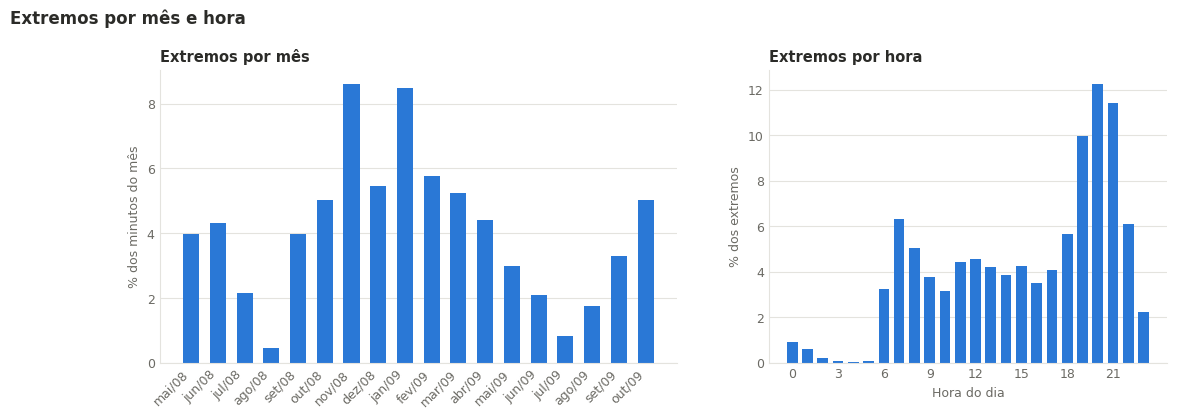

In [127]:
def plot_extremos_mes(v, caminho_png=None):
    """% de minutos extremos em cada mês e distribuição por hora do dia."""
    ext = flags[v]["extremo"]
    obs = df[v].notna()
    mes = (100 * ext.groupby(pd.Grouper(freq="MS")).sum() / obs.groupby(pd.Grouper(freq="MS")).sum())
    hora = 100 * ext.groupby(ext.index.hour).sum() / ext.sum()
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"wspace": 0.2, "width_ratios": [1.3, 1]})
    a1.bar(range(len(mes)), mes.values, width=0.6, color=AZUL)
    a1.set_xticks(range(len(mes)), [f"{MESES_PT[m.month-1]}/{m:%y}" for m in mes.index], rotation=45, ha="right")
    a1.set_ylabel("% dos minutos do mês", fontsize=9, color=TINTA_2)
    a1.set_title("Extremos por mês", fontsize=10.5, color=TINTA, loc="left", fontweight="bold")
    a2.bar(hora.index, hora.values, width=0.7, color=AZUL)
    a2.set_xticks(range(0, 24, 3))
    a2.set_xlabel("Hora do dia", fontsize=9, color=TINTA_2)
    a2.set_ylabel("% dos extremos", fontsize=9, color=TINTA_2)
    a2.set_title("Extremos por hora", fontsize=10.5, color=TINTA, loc="left", fontweight="bold")
    estilo(a1); estilo(a2)
    fig.suptitle("Extremos por mês e hora", x=0.01, ha="left", y=1.04, fontsize=12,
                 fontweight="bold", color=TINTA)
    if caminho_png:
        fig.savefig(caminho_png, dpi=150, bbox_inches="tight", facecolor="white")
    return fig


fig = plot_extremos_mes("Global_active_power", "figures/extremos_mes_hora.png")
plt.show()

#### Sumário estratificado: hora do dia × dia da semana (potência ativa)

Mediana e IQR (as medidas adequadas à forma), com o **n** de cada célula.

In [128]:
x = df[VAR_ESTRAT]
gp = x.groupby([x.index.hour, x.index.dayofweek])


def pivot(agg):
    p = gp.agg(agg).unstack()
    p.columns, p.index.name = DIAS, "hora"
    return p


p_med, p_n = pivot("median"), pivot("count")
p_iqr = pivot(lambda s: s.quantile(0.75) - s.quantile(0.25))
print(f"n por célula (hora x dia): mín = {p_n.values.min()}, máx = {p_n.values.max()} "
      f"| células com n < 30: {(p_n < 30).sum().sum()} de {p_n.size}")
p_med.round(2).style.background_gradient(cmap="Blues", axis=None).format("{:.2f}")

n por célula (hora x dia): mín = 4589, máx = 4740 | células com n < 30: 0 de 168


,Seg,Ter,Qua,Qui,Sex,Sáb,Dom
hora,,,,,,,
0,0.33,0.33,0.34,0.32,0.34,0.33,0.64
1,0.32,0.32,0.31,0.31,0.31,0.32,0.43
2,0.32,0.31,0.31,0.31,0.30,0.31,0.37
3,0.32,0.31,0.31,0.30,0.31,0.31,0.32
4,0.32,0.31,0.31,0.31,0.31,0.30,0.32
5,0.31,0.30,0.31,0.30,0.31,0.31,0.31
6,0.37,0.38,0.39,0.40,0.37,0.33,0.31
7,1.75,1.72,1.77,1.59,1.66,1.40,0.32
8,1.39,1.46,1.42,1.41,1.44,1.42,0.40


O **n** de cada célula (minutos observados):

In [129]:
p_n

,Seg,Ter,Qua,Qui,Sex,Sáb,Dom
hora,,,,,,,
0,4620,4680,4680,4740,4740,4710,4620
1,4620,4680,4680,4740,4740,4680,4620
2,4620,4680,4680,4740,4740,4680,4620
3,4620,4680,4680,4740,4740,4680,4620
4,4620,4677,4680,4740,4740,4680,4620
5,4620,4680,4680,4680,4740,4680,4620
6,4620,4680,4680,4680,4740,4680,4620
7,4645,4680,4680,4680,4740,4680,4620
8,4680,4680,4678,4680,4740,4680,4620


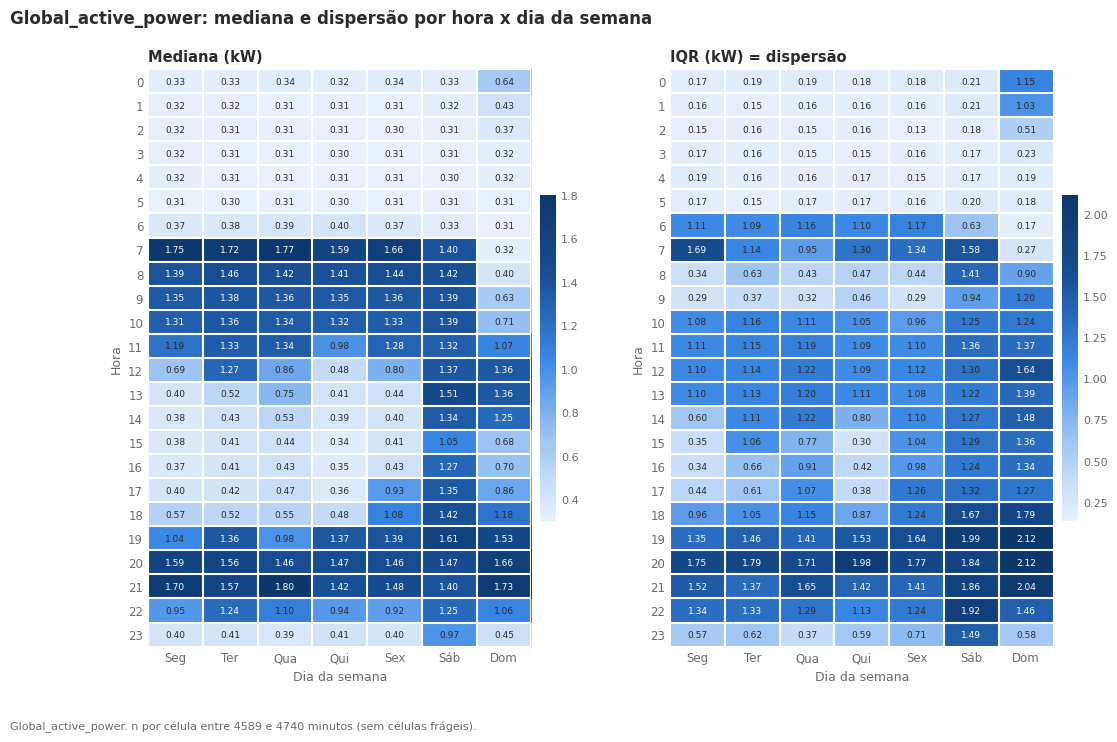

In [130]:
def plot_pivot(p_med, p_iqr, p_n, caminho_png=None):
    fig, axes = plt.subplots(1, 2, figsize=(12, 7.5), gridspec_kw={"wspace": 0.28})
    for ax, p, t in zip(axes, [p_med, p_iqr], ["Mediana (kW)", "IQR (kW) = dispersão"]):
        im = ax.imshow(p.values, aspect="auto", cmap=CMAP)
        ax.set_xticks(range(7), DIAS); ax.set_yticks(range(24), range(24))
        ax.set_xlabel("Dia da semana", fontsize=9, color=TINTA_2); ax.set_ylabel("Hora", fontsize=9, color=TINTA_2)
        ax.set_xticks(np.arange(-0.5, 7, 1), minor=True); ax.set_yticks(np.arange(-0.5, 24, 1), minor=True)
        ax.grid(which="minor", color="white", lw=1.5); ax.tick_params(which="both", length=0, labelsize=8.5, colors=TINTA_2)
        for sp in ax.spines.values(): sp.set_visible(False)
        lim = p.values.min() + 0.6 * (p.values.max() - p.values.min())
        for i in range(24):
            for j in range(7):
                ax.text(j, i, f"{p.values[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                        color="white" if p.values[i, j] > lim else TINTA)
        ax.set_title(t, loc="left", fontsize=10.5, color=TINTA, fontweight="bold")
        cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.outline.set_visible(False)
        cb.ax.tick_params(labelsize=8, colors=TINTA_2, length=0)
    fig.suptitle("Global_active_power: mediana e dispersão por hora x dia da semana",
                 x=0.01, ha="left", y=0.96, fontsize=12, fontweight="bold", color=TINTA)
    fig.text(0.01, 0.0, f"Global_active_power. n por célula entre {p_n.values.min()} e {p_n.values.max()} minutos "
             f"(sem células frágeis).", fontsize=8, color=TINTA_2)
    if caminho_png:
        fig.savefig(caminho_png, dpi=150, bbox_inches="tight", facecolor="white")
    return fig


fig = plot_pivot(p_med, p_iqr, p_n, "figures/pivot_hora_dia.png")
plt.show()

**Leitura.**

- **Fiabilidade:** cada célula tem entre 4 589 e 4 740 minutos; nenhuma é frágil (n < 30).
- **Dias úteis (seg–sex):** consumo de base de ~0,3 kW de madrugada, **pico às 7h** (mediana 1,6–1,8 kW) e **às 20–21h** (1,4–1,8 kW), e consumo baixo entre as 14h e as 16h (mediana 0,34–0,53 kW): a casa está tipicamente vazia de dia.
- **Fim de semana:** o consumo mantém-se alto durante o dia (sáb 13h: 1,51 kW; dom 12h–14h: 1,25–1,36 kW), ou seja, a casa está ocupada.
- **Domingo de manhã:** mediana de 0,31–0,40 kW às 6h–8h, contra 1,6–1,8 kW nos dias úteis: levantam-se mais tarde.
- **Fim de noite de sábado para domingo:** mediana de 0,97 kW às 23h de sábado e 0,64 kW à 0h de domingo (0,33 nos outros dias), com IQR de 1,15 kW: a atividade prolonga-se pela madrugada.
- **Dispersão:** o IQR é máximo ao fim da tarde e à noite (~2 kW ao domingo às 19h–21h) e nas horas de transição, onde o consumo varia muito entre dias; de madrugada (3h–5h) é pequeno (0,15–0,23 kW).

## Parte II — Compreender

### 2.1 Análise descritiva e diagnóstica

**Preparação.** Constrói-se a tabela diária de energia (kWh/dia), só com os **dias válidos** da 1.2, decomposta por circuito. A parte «Outros» é o que as 3 submedições não medem: `potência ativa × 1000/60 − Sub 1 − Sub 2 − Sub 3` (Wh por minuto), como indica a documentação do dataset (UCI). Segundo a mesma documentação, a **Sub 1** é a cozinha (máquina de lavar loiça, forno e micro-ondas; as placas são a gás), a **Sub 2** a lavandaria (máquina de lavar, secador, **frigorífico** e uma luz) e a **Sub 3** o aquecedor de água e o ar condicionado.

In [131]:
# Configuração da secção 2.1
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
COMP = ["aquecimento_aguas", "outros", "cozinha", "lavandaria"]            # ordem fixa = cor fixa
NOME = {"aquecimento_aguas": "Aquecedor de água + AC (Sub 3)", "outros": "Outros, não submedidos",
        "cozinha": "Cozinha (Sub 1)", "lavandaria": "Lavandaria + frigorífico (Sub 2)"}
COR = {"aquecimento_aguas": "#2a78d6", "outros": "#eb6834", "cozinha": "#1baf7a", "lavandaria": "#eda100"}
ESTACOES = {12: "Inverno", 1: "Inverno", 2: "Inverno", 3: "Primavera", 4: "Primavera", 5: "Primavera",
            6: "Verão", 7: "Verão", 8: "Verão", 9: "Outono", 10: "Outono", 11: "Outono"}
ORDEM_EST = ["Inverno", "Primavera", "Verão", "Outono"]

# Energia por minuto (Wh) e a sua decomposição (o que as 3 submedições não medem = "outros")
wh = tratado["Global_active_power"] * 1000 / 60
comp = pd.DataFrame({"cozinha": tratado["Sub_metering_1"], "lavandaria": tratado["Sub_metering_2"],
                     "aquecimento_aguas": tratado["Sub_metering_3"]})
comp["outros"] = wh - comp[["cozinha", "lavandaria", "aquecimento_aguas"]].sum(axis=1)
comp["total"] = wh

# Tabela diária (kWh/dia), só com os dias válidos da 1.2
diario = comp.resample("D").sum(min_count=1) / 1000
diario = diario[diario.index.isin(validos)]
print(f"{len(diario)} dias válidos | média {diario['total'].mean():.1f} kWh/dia | mediana {diario['total'].median():.1f}")
diario.head(3).round(2)

545 dias válidos | média 24.2 kWh/dia | mediana 24.2


,cozinha,lavandaria,aquecimento_aguas,outros,total
datetime,,,,,
2008-05-01,0.00,0.53,2.59,6.48,9.60
2008-05-02,3.11,0.58,8.69,12.58,24.96
2008-05-03,1.00,0.54,6.54,13.42,21.49


**Dias de consumo muito baixo.** Procuram-se sequências de dias seguidos com menos de 40 % do consumo diário mediano. A mais longa é o padrão que vai ser investigado no diagnóstico; nas figuras de sazonalidade os seus dias são retirados dos cálculos de «verão» e «semana típica», para que um acontecimento isolado não passe por padrão sazonal.

In [132]:
# Dias de consumo muito baixo (< 40 % da mediana diária): sequências de >= 2 dias consecutivos
limiar_baixo = 0.4 * diario["total"].median()
baixo = diario["total"] < limiar_baixo
seq = (baixo != baixo.shift()).cumsum()[baixo]
corridas = (diario[baixo].groupby(seq)
            .agg(inicio=("total", lambda s: s.index[0]), fim=("total", lambda s: s.index[-1]),
                 dias=("total", "size"), kWh_dia=("total", "mean")))
corridas = corridas[corridas["dias"] >= 2].sort_values("dias", ascending=False).reset_index(drop=True)
corridas["kWh_dia"] = corridas["kWh_dia"].round(1)
print(f"Limiar: {limiar_baixo:.1f} kWh/dia")
corridas

Limiar: 9.7 kWh/dia


,inicio,fim,dias,kWh_dia
0,2008-08-06,2008-08-30,25,4.8
1,2009-08-02,2009-08-08,7,8.6
2,2009-07-24,2009-07-26,3,9.1
3,2008-08-02,2008-08-03,2,8.4
4,2009-07-12,2009-07-13,2,8.4
5,2008-10-26,2008-10-27,2,8.7


In [133]:
# A sequência mais longa é o padrão a investigar
AUS_INI, AUS_FIM = corridas.loc[0, "inicio"], corridas.loc[0, "fim"]
em_aus = (diario.index >= AUS_INI) & (diario.index <= AUS_FIM)
REF_INI, REF_FIM = pd.Timestamp("2008-09-01"), pd.Timestamp("2008-09-30")      # mês seguinte, como referência
print(f"Padrão a investigar: {AUS_INI:%d/%m/%Y} a {AUS_FIM:%d/%m/%Y} ({corridas.loc[0, 'dias']} dias, "
      f"{corridas.loc[0, 'kWh_dia']} kWh/dia). A segunda sequência mais longa tem {corridas.loc[1, 'dias']} dias.")

Padrão a investigar: 06/08/2008 a 30/08/2008 (25 dias, 4.8 kWh/dia). A segunda sequência mais longa tem 7 dias.


#### Sazonalidade anual

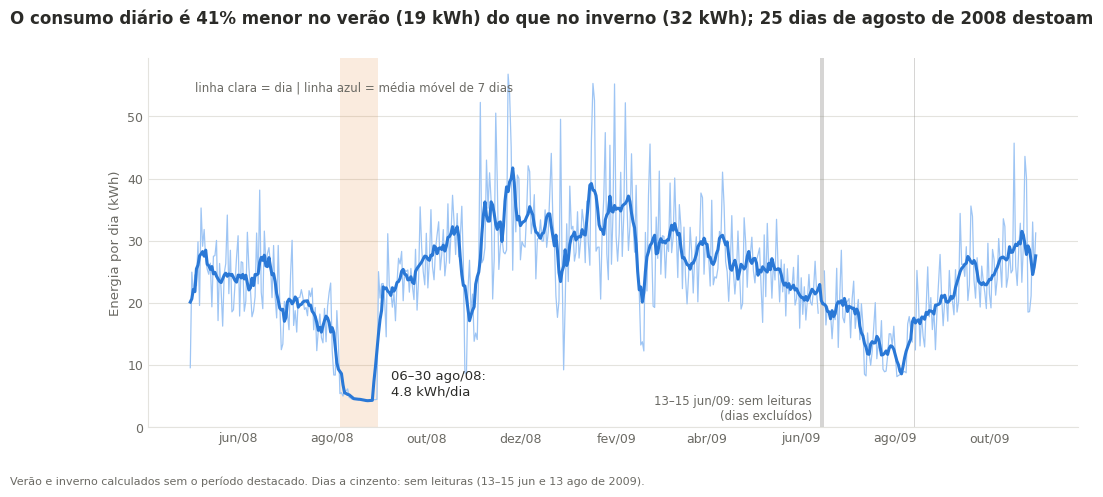

In [134]:
def plot_serie_diaria(diario, ini, fim, caminho_png=None):
    """Anual: consumo diário, média móvel de 7 dias e dias excluídos."""
    dias = pd.date_range(diario.index.min(), diario.index.max())
    s = diario["total"].reindex(dias)                               # NaN nos dias excluídos (1.2)
    sem_aus = diario.loc[~((diario.index >= ini) & (diario.index <= fim)), "total"]
    inv = sem_aus[sem_aus.index.month.isin([12, 1, 2])].mean()
    ver = sem_aus[sem_aus.index.month.isin([6, 7, 8])].mean()
    fig, ax = plt.subplots(figsize=(12, 4.8))
    ax.plot(s.index, s.values, color="#9ec5f4", lw=0.9)
    ax.plot(s.index, s.rolling(7, center=True, min_periods=4).mean(), color=AZUL, lw=2.2)
    ax.axvspan(ini, fim + pd.Timedelta(days=1), color=LARANJA, alpha=0.15, lw=0)
    ax.text(fim + pd.Timedelta(days=9), 7, f"{ini:%d}–{fim:%d} ago/08:\n{diario.loc[ini:fim, 'total'].mean():.1f} kWh/dia",
            fontsize=9.5, color=TINTA, va="center")
    falta = s[s.isna()].index
    for d in falta:
        ax.axvspan(d, d + pd.Timedelta(days=1), color="#8a8984", alpha=0.35, lw=0)
    ax.text(falta[0] - pd.Timedelta(days=5), 3, "13–15 jun/09: sem leituras\n(dias excluídos)", fontsize=8.5,
            color=TINTA_2, ha="right", va="center")
    ax.set_ylim(0, None)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: (lambda d: f"{MESES_PT[d.month - 1]}/{d:%y}")(mdates.num2date(x))))
    ax.set_ylabel("Energia por dia (kWh)", fontsize=9.5, color=TINTA_2)
    estilo(ax)
    ax.text(s.index[3], s.max() * 0.98, "linha clara = dia | linha azul = média móvel de 7 dias",
            fontsize=8.5, color=TINTA_2, va="top")
    fig.suptitle(f"O consumo diário é {1 - ver / inv:.0%} menor no verão ({ver:.0f} kWh) do que no inverno ({inv:.0f} kWh); "
                 f"25 dias de agosto de 2008 destoam", x=0.01, ha="left", fontsize=12, fontweight="bold", color=TINTA)
    fig.text(0.01, -0.01, "Verão e inverno calculados sem o período destacado. Dias a cinzento: sem leituras (13–15 jun e 13 ago de 2009).",
             fontsize=8, color=TINTA_2)
    if caminho_png:
        fig.savefig(caminho_png, dpi=150, bbox_inches="tight", facecolor="white")
    return fig


fig = plot_serie_diaria(diario, AUS_INI, AUS_FIM, "figures/2_1_anual_serie.png")
plt.show()

**Leitura.** O consumo diário é mais alto no outono e inverno e desce no verão: **31,5 kWh/dia** em dez–fev contra **18,5 kWh/dia** em jun–ago (−41 %, sem o período destacado). Os dias mais altos (até 57 kWh em 23/11/2008 e 55 kWh em 17/01/2009) ocorrem fora do verão e a série é mais irregular nessa altura. O verão de 2009 também é baixo (jul 14,8 e ago 15,8 kWh/dia), mas muito menos do que o período de agosto de 2008 (6,6 kWh/dia em média nesse mês), que destoa de tudo o resto.

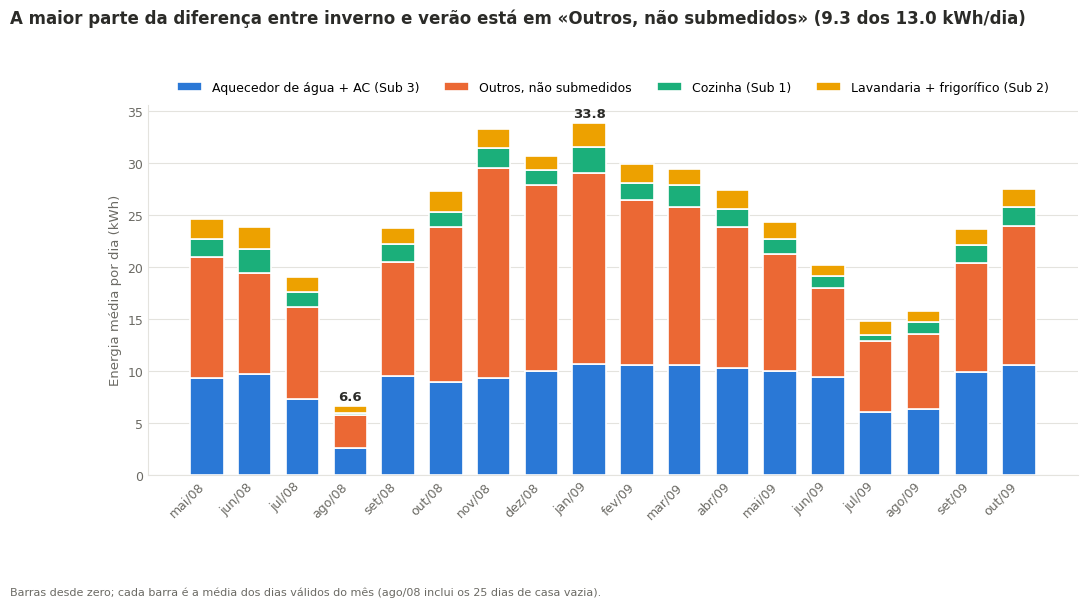

In [135]:
def plot_composicao_mensal(diario, caminho_png=None):
    """Anual: energia média por dia em cada mês, decomposta por circuito."""
    m = diario.resample("MS").mean()
    fig, ax = plt.subplots(figsize=(12, 4.8))
    base = np.zeros(len(m))
    for c in COMP:
        ax.bar(range(len(m)), m[c], bottom=base, width=0.7, color=COR[c], edgecolor="white", lw=1.2, label=NOME[c])
        base += m[c].values
    ax.set_xticks(range(len(m)), [f"{MESES_PT[d.month - 1]}/{d:%y}" for d in m.index], rotation=45, ha="right")
    ax.set_ylabel("Energia média por dia (kWh)", fontsize=9.5, color=TINTA_2)
    estilo(ax)
    for i in [int(np.argmax(m["total"])), int(np.argmin(m["total"]))]:
        ax.annotate(f"{m['total'].iloc[i]:.1f}", (i, m["total"].iloc[i]), xytext=(0, 4), textcoords="offset points",
                    ha="center", fontsize=9.5, color=TINTA, fontweight="bold")
    ax.legend(ncol=4, frameon=False, fontsize=9, loc="lower center", bbox_to_anchor=(0.5, 1.0))
    inv = diario[diario.index.month.isin([12, 1, 2])].mean()
    ver = diario[diario.index.month.isin([6, 7, 8]) & ~((diario.index >= AUS_INI) & (diario.index <= AUS_FIM))].mean()
    maior = (inv - ver)[COMP].idxmax()
    fig.suptitle(f"A maior parte da diferença entre inverno e verão está em «{NOME[maior]}» "
                 f"({(inv - ver)[maior]:.1f} dos {(inv - ver)['total']:.1f} kWh/dia)", x=0.01, ha="left", y=1.08,
                 fontsize=12, fontweight="bold", color=TINTA)
    fig.text(0.01, -0.14, "Barras desde zero; cada barra é a média dos dias válidos do mês (ago/08 inclui os 25 dias de casa vazia).",
             fontsize=8, color=TINTA_2)
    if caminho_png:
        fig.savefig(caminho_png, dpi=150, bbox_inches="tight", facecolor="white")
    return fig


fig = plot_composicao_mensal(diario, "figures/2_1_anual_composicao.png")
plt.show()

In [136]:
# De onde vem a diferença entre inverno e verão? (sem o período destacado)
sem = diario[~((diario.index >= AUS_INI) & (diario.index <= AUS_FIM))]
inv, ver = sem[sem.index.month.isin([12, 1, 2])].mean(), sem[sem.index.month.isin([6, 7, 8])].mean()
dif = pd.DataFrame({"inverno (kWh/dia)": inv, "verão (kWh/dia)": ver})
dif["diferença"] = dif.iloc[:, 0] - dif.iloc[:, 1]
dif["% da diferença total"] = (100 * dif["diferença"] / dif.loc["total", "diferença"]).round(0)
dif.loc[COMP + ["total"]].round(2).rename(index=NOME | {"total": "TOTAL"})

,inverno (kWh/dia),verão (kWh/dia),diferença,% da diferença total
Aquecedor de água + AC (Sub 3),10.38,7.65,2.73,21.0
"Outros, não submedidos",17.47,8.14,9.33,72.0
Cozinha (Sub 1),1.85,1.30,0.55,4.0
Lavandaria + frigorífico (Sub 2),1.81,1.45,0.36,3.0
TOTAL,31.52,18.54,12.98,100.0


**Leitura.** **72 %** da diferença entre inverno e verão (9,3 de 13,0 kWh/dia) vem de «Outros», o consumo que as submedições não cobrem; o aquecedor de água e AC explica 21 % e a cozinha e a lavandaria só 7 %. Como «Outros» agrega iluminação, eletrónica e qualquer equipamento não submedido, **não se consegue dizer o que o causa** (noites mais longas, aquecimento elétrico, mais tempo em casa) sem mais dados, por exemplo temperatura.

#### Sazonalidade semanal

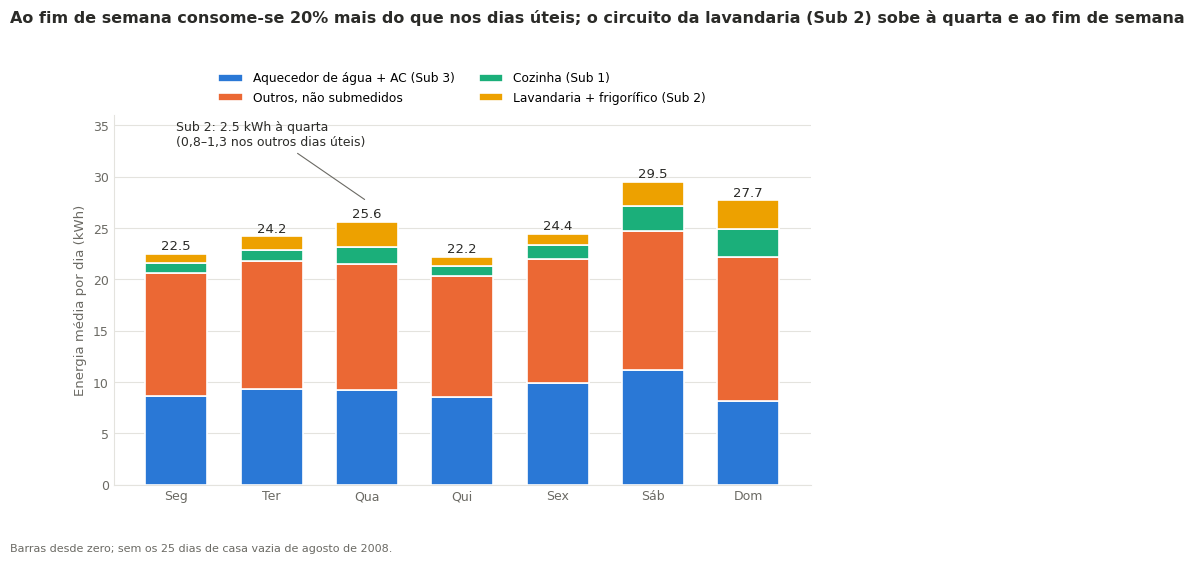

In [137]:
def plot_semana(diario, caminho_png=None):
    """Semanal: energia média por dia da semana, por circuito (sem o período destacado)."""
    d = diario.loc[~((diario.index >= AUS_INI) & (diario.index <= AUS_FIM))]
    m = d.groupby(d.index.dayofweek).mean()
    fig, ax = plt.subplots(figsize=(9, 4.8))
    base = np.zeros(7)
    for c in COMP:
        ax.bar(range(7), m[c], bottom=base, width=0.65, color=COR[c], edgecolor="white", lw=1.2, label=NOME[c])
        base += m[c].values
    ax.set_xticks(range(7), DIAS)
    ax.set_ylabel("Energia média por dia (kWh)", fontsize=9.5, color=TINTA_2)
    estilo(ax)
    for i, v in enumerate(m["total"]):
        ax.text(i, v + 0.4, f"{v:.1f}", ha="center", fontsize=9.5, color=TINTA)
    lav = m["lavandaria"]
    ax.annotate(f"Sub 2: {lav.iloc[2]:.1f} kWh à quarta\n(0,8–1,3 nos outros dias úteis)", xy=(2, m["total"].iloc[2] + 2.0),
                xytext=(0.0, 33.0), fontsize=9, color=TINTA, arrowprops=dict(arrowstyle="-", color=TINTA_2, lw=0.8))
    ax.set_ylim(0, 36)
    ax.legend(ncol=2, frameon=False, fontsize=8.8, loc="lower center", bbox_to_anchor=(0.5, 1.0))
    fds, util = m["total"].iloc[5:].mean(), m["total"].iloc[:5].mean()
    fig.suptitle(f"Ao fim de semana consome-se {fds / util - 1:.0%} mais do que nos dias úteis; "
                 f"o circuito da lavandaria (Sub 2) sobe à quarta e ao fim de semana", x=0.01, ha="left", y=1.1, fontsize=11.5,
                 fontweight="bold", color=TINTA)
    fig.text(0.01, -0.03, "Barras desde zero; sem os 25 dias de casa vazia de agosto de 2008.", fontsize=8, color=TINTA_2)
    if caminho_png:
        fig.savefig(caminho_png, dpi=150, bbox_inches="tight", facecolor="white")
    return fig


fig = plot_semana(diario, "figures/2_1_semanal.png")
plt.show()

**Leitura.** O fim de semana consome **20 % mais** do que os dias úteis (28,6 contra 23,8 kWh/dia em média), com o sábado no máximo (29,5 kWh). Entre os dias úteis, a quarta-feira destaca-se (25,6 kWh): a Sub 2 (lavandaria e frigorífico) gasta 2,5 kWh à quarta contra 0,8–1,3 kWh nos outros dias úteis, o que é compatível com um dia de lavagens (hipótese; o frigorífico contribui com um valor aproximadamente constante todos os dias).

#### Sazonalidade diária, por estação (small multiples)

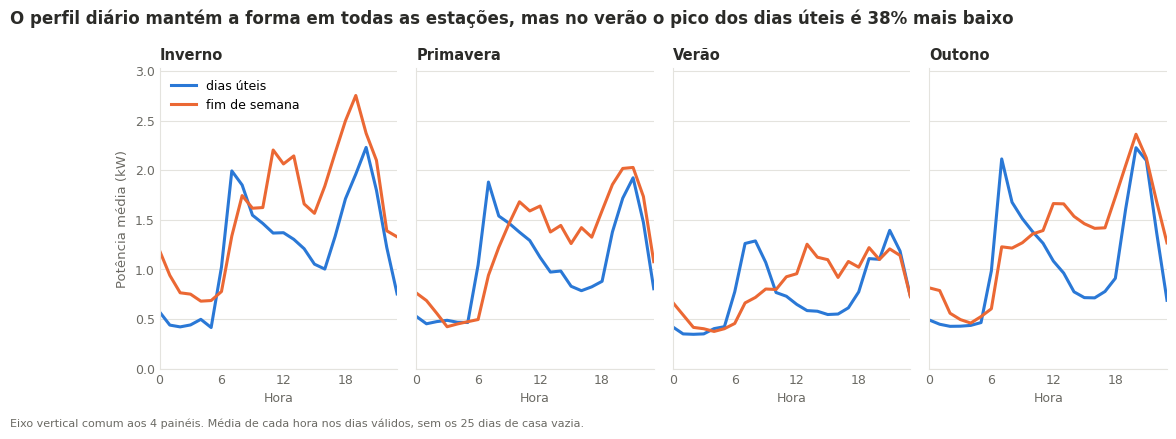

In [138]:
def plot_perfis_estacao(caminho_png=None):
    """Diária x anual (small multiples): perfil horário médio por estação, dias úteis vs fim de semana."""
    g = tratado["Global_active_power"]
    ok = g.index.normalize().isin(validos) & ~((g.index >= AUS_INI) & (g.index < AUS_FIM + pd.Timedelta(days=1)))
    g = g[ok]
    t = pd.DataFrame({"kw": g.values, "est": g.index.month.map(ESTACOES), "fds": g.index.dayofweek >= 5,
                      "h": g.index.hour})
    p = t.groupby(["est", "fds", "h"])["kw"].mean()
    ymax = p.max() * 1.1
    fig, axes = plt.subplots(1, 4, figsize=(13, 3.9), sharey=True, gridspec_kw={"wspace": 0.08})
    for ax, e in zip(axes, ORDEM_EST):
        ax.plot(range(24), p[e][False], color=AZUL, lw=2.2, label="dias úteis")
        ax.plot(range(24), p[e][True], color="#eb6834", lw=2.2, label="fim de semana")
        ax.set_title(e, loc="left", fontsize=10.5, color=TINTA, fontweight="bold")
        ax.set_xticks([0, 6, 12, 18]); ax.set_xlim(0, 23); ax.set_ylim(0, ymax)
        ax.set_xlabel("Hora", fontsize=9, color=TINTA_2)
        estilo(ax)
    axes[0].set_ylabel("Potência média (kW)", fontsize=9.5, color=TINTA_2)
    axes[0].legend(frameon=False, fontsize=9, loc="upper left")
    inv, ver = p["Inverno"][False].max(), p["Verão"][False].max()
    fig.suptitle(f"O perfil diário mantém a forma em todas as estações, mas no verão o pico dos dias úteis é "
                 f"{1 - ver / inv:.0%} mais baixo", x=0.01, ha="left", y=1.03, fontsize=12, fontweight="bold", color=TINTA)
    fig.text(0.01, -0.04, "Eixo vertical comum aos 4 painéis. Média de cada hora nos dias válidos, sem os 25 dias de casa vazia.",
             fontsize=8, color=TINTA_2)
    if caminho_png:
        fig.savefig(caminho_png, dpi=150, bbox_inches="tight", facecolor="white")
    return fig


fig = plot_perfis_estacao("figures/2_1_diaria_estacoes.png")
plt.show()

**Leitura.** A forma do dia é a mesma nas quatro estações: nos dias úteis há um pico por volta das 7h e outro às 20–21h, com consumo baixo a meio do dia; ao fim de semana o pico da manhã desloca-se para as 10–11h e o consumo diurno é mais alto. O que muda é a **escala**: o pico dos dias úteis é **38 % mais baixo no verão** (1,39 kW) do que no inverno (2,23 kW). No inverno, as noites de fim de semana também são mais ativas (0,75 kW às 3h contra 0,44 kW nos dias úteis) e o pico de sábado/domingo à noite chega a 2,75 kW (19h).

### Diagnóstico: o que aconteceu em agosto de 2008?

**Padrão escolhido.** A sequência de dias de consumo muito baixo mais longa tem **25 dias seguidos (6 a 30 de agosto de 2008) a 4,8 kWh/dia**, contra cerca de 24 kWh/dia no conjunto dos dias válidos; a segunda mais longa tem 7 dias (2 a 8 de agosto de 2009, a 8,6 kWh/dia). Não é uma lacuna de medição (esses dias estão todos na tabela de dias válidos, sem minutos em falta) nem um valor extremo isolado, é uma **quebra persistente**. O que a explica?

**Drill-down** (do mais agregado ao mais fino), comparando com setembro de 2008 como referência:

In [139]:
def metricas(mask_t):
    """Indicadores de um período (máscara sobre o índice minuto a minuto)."""
    x = tratado.loc[mask_t]
    d = diario.loc[(diario.index >= x.index[0].normalize()) & (diario.index <= x.index[-1].normalize())]
    horario = x["Global_active_power"].groupby(x.index.hour).mean()
    fds = d.groupby(d.index.dayofweek >= 5)["total"].mean()
    return {
        "Energia por dia (kWh)": d["total"].mean(),
        "Variação entre dias (desvio-padrão, kWh)": d["total"].std(),
        "Diferença fim de semana − dias úteis (kWh/dia)": fds.get(True, np.nan) - fds.get(False, np.nan),
        "Amplitude do perfil horário (pico − vale, kW)": horario.max() - horario.min(),
        "Potência média às 0–5h (kW)": horario.loc[0:5].mean(),
        "% minutos com cozinha > 0": 100 * (x["Sub_metering_1"] > 0).mean(),
        "% minutos com lavandaria > 0": 100 * (x["Sub_metering_2"] > 0).mean(),
        "% minutos com aquecedor/AC > 0": 100 * (x["Sub_metering_3"] > 0).mean(),
        "Aquecedor/AC (Wh por minuto)": x["Sub_metering_3"].mean(),
        "Tensão média (V)": x["Voltage"].mean(),
        "Minutos com potência > 1 kW": int((x["Global_active_power"] > 1).sum()),
    }


m_aus = (tratado.index >= AUS_INI) & (tratado.index < AUS_FIM + pd.Timedelta(days=1))
m_ref = (tratado.index >= REF_INI) & (tratado.index < REF_FIM + pd.Timedelta(days=1))
quadro = pd.DataFrame({"período destacado": metricas(m_aus), "referência (set/08)": metricas(m_ref)})
quadro["variação"] = ((quadro["período destacado"] / quadro["referência (set/08)"] - 1) * 100).round(0).astype("Int64").astype(str) + " %"
quadro.round(2)

,período destacado,referência (set/08),variação
Energia por dia (kWh),4.76,23.70,-80 %
"Variação entre dias (desvio-padrão, kWh)",0.58,4.24,-86 %
Diferença fim de semana − dias úteis (kWh/dia),0.14,5.02,-97 %
"Amplitude do perfil horário (pico − vale, kW)",0.05,1.70,-97 %
Potência média às 0–5h (kW),0.20,0.39,-48 %
% minutos com cozinha > 0,0.00,10.10,-100 %
% minutos com lavandaria > 0,22.87,24.50,-7 %
% minutos com aquecedor/AC > 0,67.85,77.88,-13 %
Aquecedor/AC (Wh por minuto),1.20,6.58,-82 %
Tensão média (V),240.83,240.12,0 %


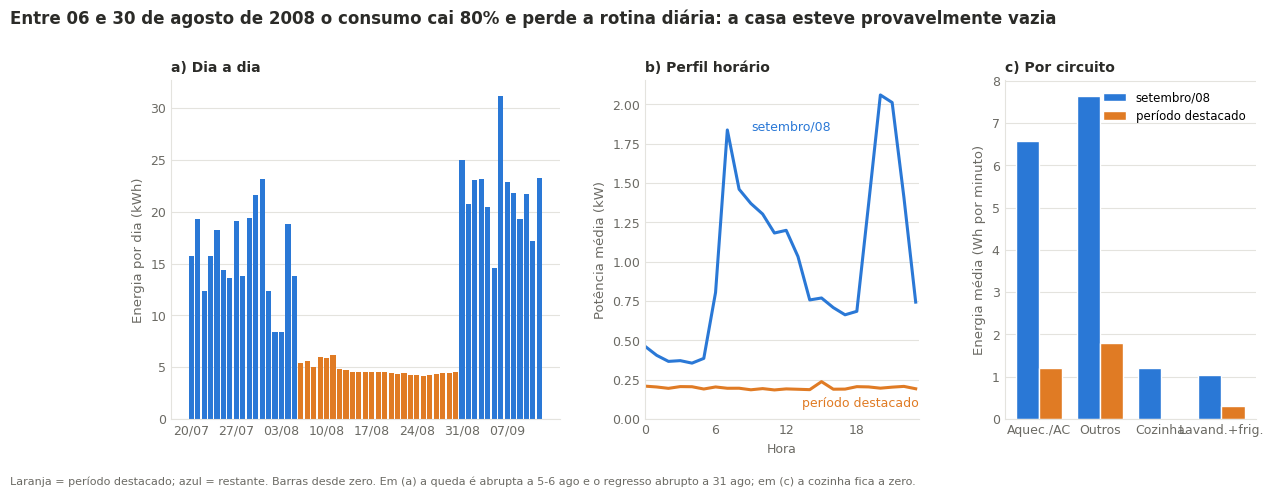

In [140]:
def plot_diagnostico(caminho_png=None):
    """Drill-down do padrão: (a) dias, (b) perfil horário, (c) circuitos."""
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1.7, 1.2, 1.1], "wspace": 0.28})
    a, b, c = axes
    # (a) dia a dia
    j = diario.loc[AUS_INI - pd.Timedelta(days=17): AUS_FIM + pd.Timedelta(days=13), "total"]
    cores = [LARANJA if (AUS_INI <= d <= AUS_FIM) else AZUL for d in j.index]
    a.bar(range(len(j)), j.values, width=0.8, color=cores)
    a.set_xticks(range(0, len(j), 7), [f"{d:%d/%m}" for d in j.index[::7]])
    a.set_ylabel("Energia por dia (kWh)", fontsize=9.5, color=TINTA_2)
    a.set_title("a) Dia a dia", loc="left", fontsize=10, color=TINTA, fontweight="bold")
    estilo(a)
    # (b) perfil horário
    for mask, cor, nome in [(m_aus, LARANJA, "período destacado"), (m_ref, AZUL, "setembro/08")]:
        x = tratado.loc[mask, "Global_active_power"]
        h = x.groupby(x.index.hour).mean()
        b.plot(h.index, h.values, color=cor, lw=2.2)
        if cor == AZUL:
            b.text(9.0, 1.86, nome, color=cor, fontsize=9, ha="left", va="center")
        else:
            b.text(23.3, 0.1, nome, color=cor, fontsize=9, ha="right", va="center")
    b.set_xticks([0, 6, 12, 18]); b.set_xlim(0, 23.3); b.set_ylim(0, None)
    b.set_xlabel("Hora", fontsize=9, color=TINTA_2); b.set_ylabel("Potência média (kW)", fontsize=9.5, color=TINTA_2)
    b.set_title("b) Perfil horário", loc="left", fontsize=10, color=TINTA, fontweight="bold")
    estilo(b)
    # (c) circuitos
    w = 0.38
    for k, (mask, cor, nome) in enumerate([(m_ref, AZUL, "setembro/08"), (m_aus, LARANJA, "período destacado")]):
        v = [comp.loc[mask, q].mean() for q in COMP]
        c.bar(np.arange(4) + (k - 0.5) * w, v, width=w, color=cor, label=nome, edgecolor="white", lw=1)
    c.set_xticks(range(4), ["Aquec./AC", "Outros", "Cozinha", "Lavand.+frig."], fontsize=8.5)
    c.set_ylabel("Energia média (Wh por minuto)", fontsize=9.5, color=TINTA_2)
    c.set_title("c) Por circuito", loc="left", fontsize=10, color=TINTA, fontweight="bold")
    c.legend(frameon=False, fontsize=8.5, loc="upper right")
    estilo(c)
    queda = 1 - diario.loc[AUS_INI:AUS_FIM, "total"].mean() / diario.loc[REF_INI:REF_FIM, "total"].mean()
    fig.suptitle(f"Entre {AUS_INI:%d} e {AUS_FIM:%d} de agosto de 2008 o consumo cai {queda:.0%} e perde a rotina diária: "
                 f"a casa esteve provavelmente vazia", x=0.01, ha="left", y=1.04, fontsize=12, fontweight="bold", color=TINTA)
    fig.text(0.01, -0.04, "Laranja = período destacado; azul = restante. Barras desde zero. "
             "Em (a) a queda é abrupta a 5-6 ago e o regresso abrupto a 31 ago; em (c) a cozinha fica a zero.", fontsize=8, color=TINTA_2)
    if caminho_png:
        fig.savefig(caminho_png, dpi=150, bbox_inches="tight", facecolor="white")
    return fig



fig = plot_diagnostico("figures/2_1_diagnostico.png")
plt.show()

As **transições**, hora a hora (potência média em kW):

In [141]:
# As transições: potência média por hora nas vésperas da saída e do regresso
dias_t = [AUS_INI - pd.Timedelta(days=1), AUS_INI, AUS_FIM, AUS_FIM + pd.Timedelta(days=1)]
g = tratado["Global_active_power"]
trans = pd.DataFrame({f"{d:%d/%m}": g[f"{d:%Y-%m-%d}"].groupby(g[f"{d:%Y-%m-%d}"].index.hour).mean() for d in dias_t}).T
trans.round(2)

datetime,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
05/08,1.13,0.37,0.32,0.30,0.31,0.28,0.29,1.48,1.92,1.90,...,0.33,0.17,0.22,0.24,0.23,0.24,0.21,0.24,0.18,0.21
06/08,0.23,0.26,0.22,0.20,0.25,0.24,0.19,0.19,0.25,0.23,...,0.20,0.24,0.22,0.25,0.25,0.24,0.22,0.25,0.21,0.22
30/08,0.17,0.19,0.16,0.21,0.15,0.22,0.21,0.14,0.22,0.16,...,0.21,0.14,0.23,0.17,0.18,0.23,0.18,0.21,0.21,0.19
31/08,0.19,0.16,0.23,0.21,0.18,0.22,0.19,0.17,0.21,0.15,...,1.61,2.40,2.14,2.89,2.56,2.64,1.64,3.18,1.81,1.46


A 5 de agosto o consumo é normal de manhã (picos às 7h–11h) e cai para cerca de 0,3 kW a partir das 12h; a 31 de agosto mantém-se em ~0,2 kW até às 13h e sobe para 1,6 kW às 14h, com a atividade de uma casa ocupada a partir daí. Ou seja, **a queda e o regresso são abruptos e acontecem a meio do dia**.

Resta explicar os poucos minutos acima de 1 kW durante o período:

In [142]:
# Durante o período destacado ainda há minutos > 1 kW: quando ocorrem e o que os explica?
pk = tratado[m_aus & (tratado["Global_active_power"] > 1)]
ep_pk = (pk.index.to_series().diff() != pd.Timedelta("1min")).sum()
print(f"{len(pk)} minutos > 1 kW, em {pk.index.normalize().nunique()} dos {corridas.loc[0, 'dias']} dias ({ep_pk} episódios)")
print("hora com mais picos:", pk.index.hour.value_counts().head(3).to_dict(), "(hora: nº de minutos)")
print(f"potência média nesses minutos: {pk['Global_active_power'].mean():.2f} kW | "
      f"fração explicada pelo aquecedor/AC: {pk['Sub_metering_3'].mean() / (pk['Global_active_power'].mean() * 1000 / 60):.0%} "
      f"| cozinha: {pk['Sub_metering_1'].mean():.1f} Wh/min")

74 minutos > 1 kW, em 11 dos 25 dias (21 episódios)
hora com mais picos: {15: 34, 22: 7, 8: 5} (hora: nº de minutos)
potência média nesses minutos: 1.31 kW | fração explicada pelo aquecedor/AC: 33% | cozinha: 0.0 Wh/min


#### Resumo do drill-down

| Nível | O que se vê |
|---|---|
| **Mês** | ago/08 tem 6,6 kWh/dia, o mínimo dos 18 meses (o seguinte, jul/09, tem 14,8). |
| **Dia** | 25 dias seguidos (6–30 ago) a 4,2–6,2 kWh, com início a 5/ago por volta das 12h e fim a 31/ago por volta das 14h. |
| **Semana** | Desaparece o efeito do dia da semana: a diferença fim de semana − dias úteis passa de 5,0 para 0,1 kWh/dia. |
| **Hora** | O perfil horário fica plano (amplitude de 0,05 kW contra 1,70 kW): sem pico das 7h nem das 20–21h. |
| **Circuito** | A cozinha fica a zero (0 % dos minutos com consumo contra 10,1 % em setembro); o aquecedor de água/AC cai 82 %; a Sub 2 continua ativa em 22,9 % dos minutos (contra 24,5 %), que é o que se espera de um frigorífico a ciclar. |
| **Medição** | Tensão normal (240,8 V contra 240,1 V), sem minutos em falta. |

#### Hipóteses, por ordem de plausibilidade

| # | Hipótese | Plausibilidade | A favor | Contra / limites |
|---|---|---|---|---|
| H1 | **Casa vazia durante uma ausência prolongada** (p. ex. férias) | **Alta** | Início e fim abruptos a meio do dia; 25 dias seguidos; perfil horário plano; sem efeito do dia da semana; cozinha a zero; frigorífico (Sub 2) a funcionar | Os dados mostram *ausência de atividade*, não o motivo. Agosto ser mês de férias em França é contexto externo, não está nos dados; confirmar com os residentes |
| H2 | **Equipamentos desligados ou em modo mínimo** durante a ausência (complementar a H1) | **Média-alta** | Aquecedor de água/AC −82 %; consumo às 0–5h de 0,20 kW contra 0,39 kW; os 74 minutos > 1 kW (em 11 dias) concentram-se às 15h (34 minutos) e o aquecedor/AC explica 33 % da sua potência: compatível com um temporizador | Não se consegue distinguir «desligado manualmente» de «temporizador» só com estes dados |
| H3 | **Falha ou sub-registo do sistema de medição** | **Baixa** | — | Sem minutos em falta; tensão normal; a Sub 2 continua a registar o ciclo do frigorífico; o regresso é brusco e traz o padrão normal de uma casa ocupada (cozinha incluída). Sub-registo uniforme não é testável, mas não explicaria a coincidência exata com as datas e a cozinha a zero |
| H4 | **Corte de eletricidade ou casa sem alimentação** | **Muito baixa** | — | A tensão está presente (240,8 V) e há consumo contínuo; um corte daria tensão 0 ou minutos em falta |
| H5 | **Mudança estrutural** (obras, equipamento avariado, novo tarifário) | **Muito baixa** | — | Em setembro volta ao nível de maio–junho (23,7 contra 24,6 e 23,9 kWh/dia): o efeito não é permanente |

**Como se confirmaria (fora dos dados atuais):** perguntar aos residentes, comparar com o calendário de férias escolares ou, com mais dados, ver se o padrão se repete noutros anos (o de agosto de 2009 é muito mais curto e menos profundo: 7 dias a 8,6 kWh/dia). **Implicação para a LusoEnergia:** consumos de base de ~0,2 kW (ou seja, ~4,8 kWh/dia) são o «consumo de uma casa vazia» deste cliente; um padrão destes pode servir para detetar ausências automaticamente, o que é uma boa candidata a pergunta livre.